In [1]:
import json
def load_benchmark_data(file_path):
    with open(file_path, "r") as f:
        benchmark_data = json.load(f)

    return benchmark_data

In [2]:
file_path_benchmark2 = "../results/benchmark_FlameF0X_TinyMoE-100m-2x8-retrained.json"
benchmark2_data = load_benchmark_data(file_path_benchmark2)

In [3]:
def print_benchmark_advanced(data):
    for top_k, data in data["runs"].items():
        print(f"\nTop-k: {top_k.replace('top_k_', '')}")
        print("=" * 40)
        for key, value in data["metrics"]["results"].items():
            for sub_key, sub_value in value.items():
                if sub_key.startswith("acc"):
                    print(f"{sub_key}: {sub_value * 100:.2f}%")
                else:
                    print(f"{sub_key}: {sub_value}")
            print("-" * 40)


In [4]:
print_benchmark_advanced(benchmark2_data)


Top-k: baseline
name: hellaswag
alias: hellaswag
sample_len: 10042
acc,none: 26.10%
acc_stderr,none: 0.44%
acc_norm,none: 25.91%
acc_norm_stderr,none: 0.44%
----------------------------------------
name: arc_easy
alias: arc_easy
sample_len: 2376
acc,none: 34.81%
acc_stderr,none: 0.98%
acc_norm,none: 33.84%
acc_norm_stderr,none: 0.97%
----------------------------------------
name: piqa
alias: piqa
sample_len: 1838
acc,none: 55.39%
acc_stderr,none: 1.16%
acc_norm,none: 54.79%
acc_norm_stderr,none: 1.16%
----------------------------------------
name: winogrande
alias: winogrande
sample_len: 1267
acc,none: 51.14%
acc_stderr,none: 1.40%
----------------------------------------
name: openbookqa
alias: openbookqa
sample_len: 500
acc,none: 13.40%
acc_stderr,none: 1.52%
acc_norm,none: 24.20%
acc_norm_stderr,none: 1.92%
----------------------------------------
name: lambada_openai
alias: lambada_openai
sample_len: 5153
perplexity,none: 13219.574923725932
perplexity_stderr,none: 663.402479549311

In [58]:
tasks = list(benchmark2_data['runs']['baseline']['metrics']['results'].keys())
benchmark2_results = benchmark2_data['runs']


In [61]:
def get_benchmark_runs(data):
    runs = {}
    for top_k, data in data["runs"].items():
        runs[top_k] = data["metrics"]["results"]
    return runs

benchmark_runs = get_benchmark_runs(benchmark2_data)

In [62]:
benchmark_runs

{'baseline': {'hellaswag': {'name': 'hellaswag',
   'alias': 'hellaswag',
   'sample_len': 10042,
   'acc,none': 0.2610037841067516,
   'acc_stderr,none': 0.0043828441286430965,
   'acc_norm,none': 0.2591117307309301,
   'acc_norm_stderr,none': 0.004372516060164899},
  'arc_easy': {'name': 'arc_easy',
   'alias': 'arc_easy',
   'sample_len': 2376,
   'acc,none': 0.3480639730639731,
   'acc_stderr,none': 0.00977462760025901,
   'acc_norm,none': 0.3383838383838384,
   'acc_norm_stderr,none': 0.009709034670524988},
  'piqa': {'name': 'piqa',
   'alias': 'piqa',
   'sample_len': 1838,
   'acc,none': 0.5538628944504896,
   'acc_stderr,none': 0.011597936590301249,
   'acc_norm,none': 0.5478781284004353,
   'acc_norm_stderr,none': 0.011612217507379409},
  'winogrande': {'name': 'winogrande',
   'alias': 'winogrande',
   'sample_len': 1267,
   'acc,none': 0.5114443567482242,
   'acc_stderr,none': 0.014048804199859391},
  'openbookqa': {'name': 'openbookqa',
   'alias': 'openbookqa',
   'sample

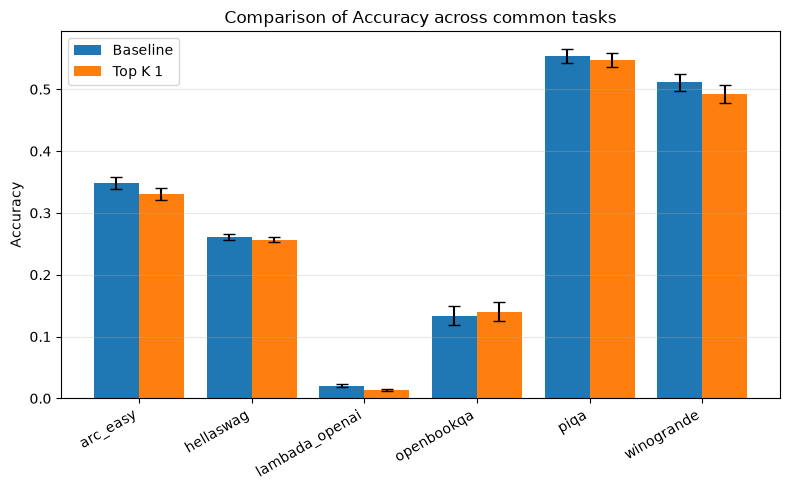

In [123]:
import numpy as np

def bar_benchmark_results(benchmark_runs, metric):
    import matplotlib.pyplot as plt

    run_names = list(benchmark_runs)
    run_names.remove("top_k_2")
    common_tasks = sorted(set.intersection(
        *(set(run_data) for run_data in benchmark_runs.values())
    ))

    x = np.arange(len(common_tasks))
    width = 0.8 / len(run_names)

    fig, ax = plt.subplots(figsize=(8, 5))

    for i, run_name in enumerate(run_names):
        run_data = benchmark_runs[run_name]
        values = [run_data[task][metric] for task in common_tasks]
        errors = [
            run_data[task].get("acc_stderr,none", 0)
            for task in common_tasks
        ]

        ax.bar(
            x + i * width,
            values,
            width,
            yerr=errors,
            capsize=4,
            label=run_name.replace("_", " ").title(),
        )

    ax.set_xticks(x + width * (len(run_names) - 1) / 2)
    ax.set_xticklabels(common_tasks, rotation=30, ha="right")
    ax.set_ylabel("Accuracy")
    ax.set_title(f"Comparison of Accuracy across common tasks")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    fig.tight_layout()
    plt.show()

bar_benchmark_results(benchmark_runs, "acc,none")

In [10]:
benchmark2_data['runs']['top_k_1']["efficiency"]

{'elapsed_seconds': 131.93624302800072}

In [11]:
benchmark2_data["runs"]['top_k_1']['efficiency'], benchmark2_data["runs"]['top_k_2']['efficiency']

({'elapsed_seconds': 131.93624302800072},
 {'elapsed_seconds': 118.03718490200026})

In [12]:
benchmark2_data["comparison"]

{'reference_top_k': 2,
 'speedup_vs_reference': {'top_k_1': 0.8946532218364693, 'top_k_2': 1.0},
 'time_reduction_percent_vs_reference': {'top_k_1': -11.775152158652435,
  'top_k_2': 0.0}}

In [13]:
benchmark2_data["metadata"]

{'model_name': 'FlameF0X/TinyMoE-100m-2x8-retrained',
 'batch_size': 10,
 'device': 'cuda',
 'dtype': 'torch.float16',
 'num_layers': 10}